<a href="https://colab.research.google.com/github/Kirthiga19/DL/blob/main/Weather.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping



In [2]:
from google.colab import files

uploaded = files.upload()

Saving 03_IyerpadiDailyFull3.0.csv to 03_IyerpadiDailyFull3.0.csv


In [3]:
df = pd.read_csv("03_IyerpadiDailyFull3.0.csv")

print(df.head())
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

         date  year  month  day  precipitation  maxTemp  minTemp  temperature  \
0  2014-01-24  2014      1   24            0.0   26.182   14.673    19.200813   
1  2014-01-25  2014      1   25            0.0   25.768   15.438    19.423458   
2  2014-01-26  2014      1   26            0.0   25.501   14.864    19.321042   
3  2014-01-27  2014      1   27            0.0   24.243   13.546    18.807708   
4  2014-01-28  2014      1   28            0.0   26.304   14.553    19.280958   

   maxRH  minRH  ...  maxgust  mingust  gustspeed  maxdew  mindew   dewpoint  \
0   90.6   59.4  ...     5.04     0.25   2.132917    18.1    12.1  14.781250   
1   92.4   54.6  ...     6.55     0.25   3.061250    17.7    12.7  14.610417   
2   84.5   45.4  ...     7.30     1.51   4.118021    14.7    11.9  13.241667   
3   84.4   55.5  ...     6.55     1.51   3.835104    15.6    10.8  13.064583   
4   83.7   42.2  ...     5.29     0.25   3.046042    15.5     6.0  11.168750   

   maxRad  minRad    radiance  d

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.dropna(subset=["date", "temperature"])
df = df.sort_values("date")
df = df.drop_duplicates(subset="date", keep="last")

df = df.set_index("date")

print("Missing values before processing:")
print(df.isnull().sum())

print("Date range:", df.index.min(), "to", df.index.max())
print("Records:", len(df))

Missing values before processing:
year             0
month            0
day              0
precipitation    0
maxTemp          0
minTemp          0
temperature      0
maxRH            0
minRH            0
humidity         0
maxwind          0
minwind          0
windspeed        0
maxgust          0
mingust          0
gustspeed        0
maxdew           0
mindew           0
dewpoint         0
maxRad           0
minRad           0
radiance         0
daylight         0
dtype: int64
Date range: 2014-01-24 00:00:00 to 2026-01-31 00:00:00
Records: 4391


In [5]:
features = [
    "temperature",
    "humidity",
    "precipitation",
    "windspeed",
    "maxTemp",
    "minTemp",
    "dewpoint",
    "radiance",
    "daylight"
]

# Keep only columns present in the dataset
features = [col for col in features if col in df.columns]

df = df[features].apply(pd.to_numeric, errors="coerce")

print("Selected features:", features)
print(df.head())


Selected features: ['temperature', 'humidity', 'precipitation', 'windspeed', 'maxTemp', 'minTemp', 'dewpoint', 'radiance', 'daylight']
            temperature   humidity  precipitation  windspeed  maxTemp  \
date                                                                    
2014-01-24    19.200813  76.133333            0.0   0.464583   26.182   
2014-01-25    19.423458  74.612500            0.0   0.639792   25.768   
2014-01-26    19.321042  69.051042            0.0   0.947292   25.501   
2014-01-27    18.807708  70.060417            0.0   1.007812   24.243   
2014-01-28    19.280958  60.162500            0.0   0.759896   26.304   

            minTemp   dewpoint    radiance  daylight  
date                                                  
2014-01-24   14.673  14.781250  534.351042     11.75  
2014-01-25   15.438  14.610417  517.059375     12.00  
2014-01-26   14.864  13.241667  543.153125     12.00  
2014-01-27   13.546  13.064583  523.101042     12.00  
2014-01-28   14.553  11

In [6]:
df = df.resample("D").mean()

df[features] = df[features].interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

df = df.dropna(subset=features)

print("Cleaned records:", len(df))
print("Number of features:", len(features))

if len(df) < 1000:
    raise ValueError("Need at least 1000 usable daily records.")

print("Data cleaning completed!")

Cleaned records: 4391
Number of features: 9
Data cleaning completed!


In [7]:
split = int(len(df) * 0.80)

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_scaler.fit(df[features].iloc[:split])
y_scaler.fit(df[["temperature"]].iloc[:split])

X_scaled = x_scaler.transform(df[features])

y_scaled = y_scaler.transform(
    df[["temperature"]]
).ravel()

print("Normalization completed!")
print("Input shape:", X_scaled.shape)

Normalization completed!
Input shape: (4391, 9)


In [8]:
LOOKBACK = 30

X = []
y = []
target_indices = []

for i in range(LOOKBACK, len(df)):
    X.append(X_scaled[i - LOOKBACK:i])
    y.append(y_scaled[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4361, 30, 9)
y shape: (4361,)


In [9]:
train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3482
Testing samples: 879


In [10]:
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(LOOKBACK, len(features))
    ),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,905 (124.63 KB)

 Trainable params: 31,905 (124.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 0.0381 - val_loss: 0.0131
Epoch 2/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0136 - val_loss: 0.0144
Epoch 3/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0118 - val_loss: 0.0158
Epoch 4/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.0113 - val_loss: 0.0161
Epoch 5/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0106 - val_loss: 0.0168
Epoch 6/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0108 - val_loss: 0.0191
Epoch 7/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.0101 - val_loss: 0.0178
Epoch 8/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0095 - val_loss: 0.0186
Epoch 9/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0088 - val_loss: 0.0174
Model training completed!


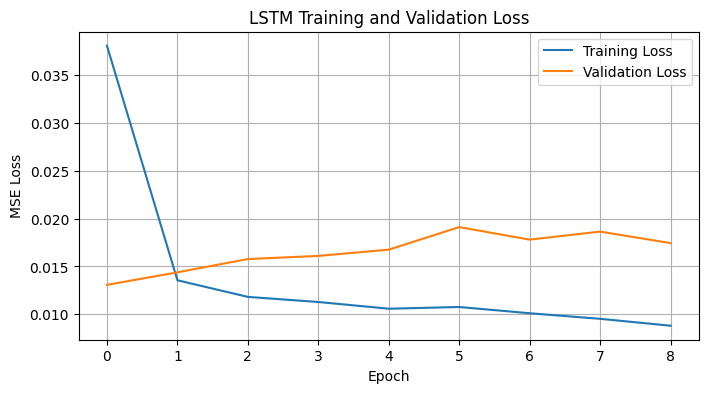

In [12]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4), "°C")

Mean Squared Error (MSE): 1.1465
Root Mean Squared Error (RMSE): 1.0707 °C


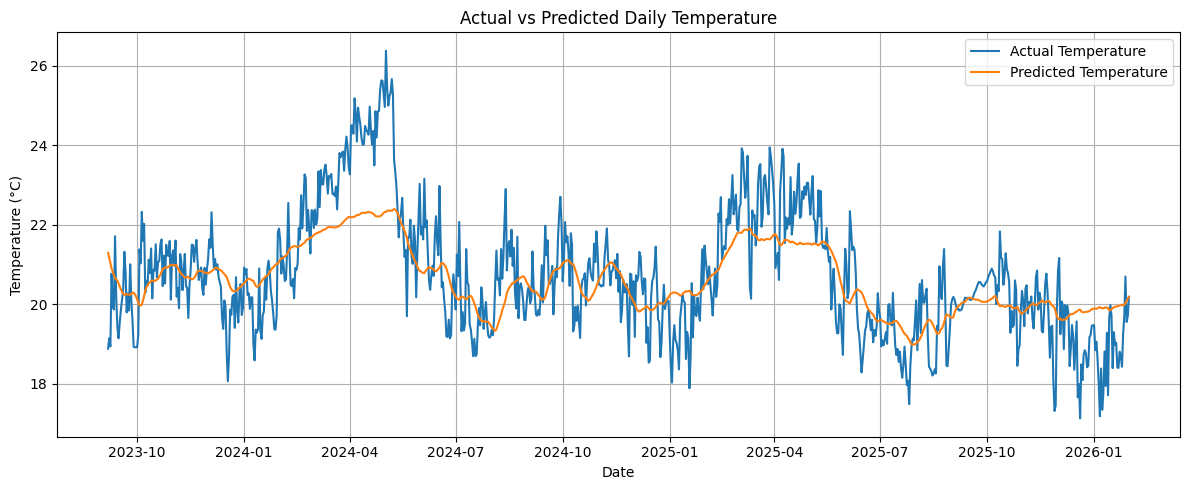

In [15]:
test_dates = df.index[target_indices[test_mask]]

plt.figure(figsize=(12, 5))

plt.plot(test_dates, actual, label="Actual Temperature")
plt.plot(test_dates, predicted, label="Predicted Temperature")

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()